In [59]:
pip install h5py scikit-learn torch pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Pipeline de Lectura y Preprocesamiento de N-CMAPSS (DS02)
# Conexión directa con la Arquitectura Híbrida (Ablación Con/Sin Atención)

In [ ]:
# # Pipeline de Lectura y Preprocesamiento de N-CMAPSS (DS02)
# Conexión directa con la Arquitectura Híbrida (Ablación Con/Sin Atención)

# %%
import os
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cpu


## 1. Carga Eficiente y Submuestreo desde el archivo HDF5 (.h5)

In [62]:
# ## 1. Carga Eficiente y Submuestreo desde el archivo HDF5 (.h5)

# %%
def load_ncmapss_subset(file_path, sample_step=10):
    """
    Lee N-CMAPSS en formato .h5 y aplica submuestreo temporal
    para controlar el consumo de memoria RAM.
    
    sample_step: Toma 1 muestra cada 'sample_step' segundos (Downsampling).
    """
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"No se encontró el archivo {file_path}. Descárgalo en la ruta indicada.")

    print(f"Abriendo {file_path}...")
    with h5py.File(file_path, 'r') as hdf:
        # Explorar llaves principales
        # Generalmente: 'W_dev', 'X_s_dev', 'X_v_dev', 'Y_dev', 'A_dev'
        print("Claves disponibles en el archivo:", list(hdf.keys()))
        
        # Leer datos de desarrollo (Train/Dev)
        # Aplicamos el slicing [::sample_step] directamente en la lectura
        W = np.array(hdf['W_dev'][::sample_step], dtype=np.float32)       # Condiciones de operación (4)
        X_s = np.array(hdf['X_s_dev'][::sample_step], dtype=np.float32)   # Sensores físicos (14)
        Y = np.array(hdf['Y_dev'][::sample_step], dtype=np.float32)       # RUL
        A = np.array(hdf['A_dev'][::sample_step], dtype=np.float32)       # Auxiliar (Unit ID, Cycle, etc.)

    print(f"Datos cargados con downsampling (1 cada {sample_step}s):")
    print(f"Condiciones W: {W.shape} | Sensores Xs: {X_s.shape} | RUL Y: {Y.shape}")
    
    # Concatenar variables predictoras: W + Xs (Total: 18 señales)
    features = np.hstack((W, X_s))
    unit_ids = A[:, 0]  # El primer campo suele ser el identificador de la unidad (engine_id)
    
    return features, Y.flatten(), unit_ids

In [63]:
# Ruta de tu archivo N-CMAPSS
DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"

In [64]:
# Cargar con paso de 10 segundos
features, ruls, unit_ids = load_ncmapss_subset(DATASET_PATH, sample_step=10)

Abriendo D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5...
Claves disponibles en el archivo: ['A_dev', 'A_test', 'A_var', 'T_dev', 'T_test', 'T_var', 'W_dev', 'W_test', 'W_var', 'X_s_dev', 'X_s_test', 'X_s_var', 'X_v_dev', 'X_v_test', 'X_v_var', 'Y_dev', 'Y_test']
Datos cargados con downsampling (1 cada 10s):
Condiciones W: (526345, 4) | Sensores Xs: (526345, 14) | RUL Y: (526345, 1)


In [65]:
# ## 3. Normalización por Condición y Ventaneo Temporal

# %%
# Estandarización de las 18 variables de entrada
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

WINDOW_SIZE = 30  # Tamaño de la ventana temporal
STRIDE = 5        # Paso entre ventanas consecutivas

def create_ncmapss_windows(features, ruls, unit_ids, window_size=30, stride=5):
    """
    Construye las ventanas deslizantes asegurando no mezclar
    trayectorias de distintas unidades de turbofán.
    """
    X_windows, y_windows = [], []
    unique_units = np.unique(unit_ids)
    
    for u in unique_units:
        mask = (unit_ids == u)
        u_feats = features[mask]
        u_ruls = ruls[mask]
        
        num_windows = (len(u_feats) - window_size) // stride + 1
        for i in range(num_windows):
            start = i * stride
            end = start + window_size
            X_windows.append(u_feats[start:end, :])
            y_windows.append(u_ruls[end - 1]) # RUL del último instante de la ventana
            
    return np.array(X_windows, dtype=np.float32), np.array(y_windows, dtype=np.float32)

X_data, y_data = create_ncmapss_windows(features_scaled, ruls, unit_ids, window_size=WINDOW_SIZE, stride=STRIDE)
print(f"Tensores finales para PyTorch: X: {X_data.shape}, y: {y_data.shape}")

Tensores finales para PyTorch: X: (105237, 30, 18), y: (105237,)


In [66]:
# ## 4. Separación y DataLoaders en PyTorch

# %%
# Train/Validation Split (80% / 20%)
split_idx = int(0.8 * len(X_data))
X_train, X_val = X_data[:split_idx], X_data[split_idx:]
y_train, y_val = y_data[:split_idx], y_data[split_idx:]

class NCMAPSSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(NCMAPSSDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(NCMAPSSDataset(X_val, y_val), batch_size=64, shuffle=False)

In [67]:
# ## 3. Arquitectura Modular con Interruptor de Ablación (Mecanismo de Atención)

# %%
class TemporalAttention(nn.Module):
    """Mecanismo de atención temporal basado en puntuación aditiva de Bahdanau."""
    def __init__(self, hidden_dim):
        super(TemporalAttention, self).__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)
        
    def forward(self, lstm_outputs):
        # lstm_outputs: (batch_size, seq_len, hidden_dim)
        energy = torch.tanh(self.attn(lstm_outputs))
        scores = self.v(energy)  # (batch_size, seq_len, 1)
        weights = torch.softmax(scores, dim=1)
        # Vector de contexto ponderado por los pesos de atención
        context = torch.sum(weights * lstm_outputs, dim=1) # (batch_size, hidden_dim)
        return context, weights

class RULPredictorAblation(nn.Module):
    """
    Arquitectura Híbrida 1D-CNN + LSTM con interruptor de Atención para Ablación.
    """
    def __init__(self, num_features, seq_length, use_attention=True):
        super(RULPredictorAblation, self).__init__()
        self.use_attention = use_attention
        
        # Extracción Espacial
        self.conv1 = nn.Conv1d(in_channels=num_features, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        
        # Modelado Temporal
        self.lstm = nn.LSTM(input_size=32, hidden_size=64, batch_first=True, num_layers=1)
        
        # Mecanismo de Atención (Ablación)
        if self.use_attention:
            self.attention = TemporalAttention(hidden_dim=64)
            
        # Cabezal de Regresión (MLP)
        self.fc = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        # x: (batch_size, seq_len, num_features)
        # Transponer para Conv1D: (batch_size, num_features, seq_len)
        x = x.permute(0, 2, 1)
        c_out = self.dropout(self.relu(self.bn1(self.conv1(x))))
        
        # Retornar a formato secuencial para LSTM: (batch_size, seq_len, channels)
        c_out = c_out.permute(0, 2, 1)
        lstm_out, (h_n, _) = self.lstm(c_out)
        
        if self.use_attention:
            context, _ = self.attention(lstm_out)
            feature_vector = context
        else:
            # Ablación: Toma directamente el último estado oculto h_T
            feature_vector = lstm_out[:, -1, :]
            
        out = self.fc(feature_vector)
        return out

In [68]:
# ## 4. Partición por Unidad, Etiquetado PwL y DataLoaders Corregidos

# %%
# 1. Aplicar recorte lineal por tramos al RUL (PwL: estándar para evitar penalizar la etapa sana)
RUL_MAX = 125.0
ruls_pwl = np.clip(ruls, 0.0, RUL_MAX)

# 2. Reconstruir ventanas con el RUL recortado
X_data, y_data = create_ncmapss_windows(features_scaled, ruls_pwl, unit_ids, window_size=WINDOW_SIZE, stride=STRIDE)

# 3. Separación Train/Val asegurando independencia temporal
split_idx = int(0.8 * len(X_data))
X_train, X_val = X_data[:split_idx], X_data[split_idx:]
y_train, y_val = y_data[:split_idx], y_data[split_idx:]

class NCMAPSSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(NCMAPSSDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(NCMAPSSDataset(X_val, y_val), batch_size=64, shuffle=False)

print(f"Pipeline preparado: X_train = {X_train.shape} | X_val = {X_val.shape}")

Pipeline preparado: X_train = (84189, 30, 18) | X_val = (21048, 30, 18)


In [69]:
# ## 5. Arquitectura Híbrida Unificada con Retorno de Pesos de Atención

# %%
class TemporalAttentionModule(nn.Module):
    def __init__(self, hidden_dim):
        super(TemporalAttentionModule, self).__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)
        
    def forward(self, lstm_out):
        # lstm_out: (Batch, Seq_Len, Hidden_Dim)
        energy = torch.tanh(self.attn(lstm_out))
        scores = self.v(energy)                          # (Batch, Seq_Len, 1)
        weights = torch.softmax(scores, dim=1)           # (Batch, Seq_Len, 1)
        context = torch.sum(weights * lstm_out, dim=1)   # (Batch, Hidden_Dim)
        return context, weights

class NCMAPSSPredictorAblation(nn.Module):
    def __init__(self, num_features=18, use_attention=True):
        super(NCMAPSSPredictorAblation, self).__init__()
        self.use_attention = use_attention
        
        # Convolución 1D sobre canales de sensores y condiciones
        self.conv1 = nn.Conv1d(in_channels=num_features, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        
        # Etapa Recurrente LSTM
        self.lstm = nn.LSTM(input_size=32, hidden_size=64, batch_first=True)
        
        # Mecanismo de Atención Temporal
        if self.use_attention:
            self.attention = TemporalAttentionModule(hidden_dim=64)
            
        # Cabezal de Regresión
        self.fc = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        # x: (Batch, Seq_Len, Features) -> (Batch, Features, Seq_Len)
        x = x.permute(0, 2, 1)
        x = self.dropout(self.relu(self.bn1(self.conv1(x))))
        x = x.permute(0, 2, 1)
        
        lstm_out, _ = self.lstm(x)
        
        weights = None
        if self.use_attention:
            feat_vector, weights = self.attention(lstm_out)
        else:
            feat_vector = lstm_out[:, -1, :]  # Último estado oculto
            
        out = self.fc(feat_vector)
        return out, weights

In [70]:
# ## 6. Bucle de Entrenamiento Parametrizable para la Prueba de Ablación

# %%
import math

def run_experiment(use_attention=True, epochs=12, lr=1e-3):
    num_features = X_train.shape[2]
    model = NCMAPSSPredictorAblation(num_features=num_features, use_attention=use_attention).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    
    history = {'train_loss': [], 'val_loss': [], 'val_rmse': []}
    tag = "CON ATENCIÓN" if use_attention else "SIN ATENCIÓN (Baseline Ablación)"
    print(f"\n=======================================================")
    print(f"       Iniciando Entrenamiento: {tag}")
    print(f"=======================================================")
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            preds, _ = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * X_b.size(0)
            
        train_loss /= len(train_loader.dataset)
        
        # Validación
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                preds, _ = model(X_b)
                loss = criterion(preds, y_b)
                val_loss += loss.item() * X_b.size(0)
                
        val_loss /= len(val_loader.dataset)
        val_rmse = math.sqrt(val_loss)
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_rmse'].append(val_rmse)
        
        if (epoch + 1) % 3 == 0 or epoch == epochs - 1:
            print(f"Época {epoch+1:02d}/{epochs:02d} -> Pérdida Train: {train_loss:.4f} | Pérdida Val: {val_loss:.4f} | Val RMSE: {val_rmse:.2f} ciclos")

    # Inferencia sobre todo el conjunto de validación
    model.eval()
    all_preds, all_weights = [], []
    with torch.no_grad():
        for X_b, _ in val_loader:
            X_b = X_b.to(device)
            preds, w = model(X_b)
            all_preds.extend(preds.cpu().numpy().flatten())
            if w is not None:
                all_weights.extend(w.squeeze(-1).cpu().numpy())
                
    return model, history, np.array(all_preds), (np.array(all_weights) if use_attention else None)

In [71]:
# ## 7. EJECUCIÓN DEL PIPELINE Y VISUALIZACIÓN DE RESULTADOS

# %%
# Forzar a VS Code a renderizar los gráficos de forma interactiva e incrustada
%matplotlib inline

# 1. Entrenar el modelo SIN atención (Línea Base / Ablación)
_, hist_no_att, preds_no_att, _ = run_experiment(use_attention=False, epochs=12)

# 2. Entrenar el modelo CON atención (Propuesta Seleccionada)
_, hist_att, preds_att, attn_weights = run_experiment(use_attention=True, epochs=12)

# 3. Vector de etiquetas reales de validación
y_val_eval = y_val.flatten()

# 4. Imprimir Tabla Comparativa Cuantitativa por Tramos
print_comparative_table(y_val_eval, preds_no_att, preds_att)

# 5. Generar y desplegar el Panel de 4 Gráficos
plot_ablation_results(
    y_test_true=y_val_eval,
    y_pred_no_att=preds_no_att,
    y_pred_att=preds_att,
    history_no_att=hist_no_att,
    history_att=hist_att,
    attention_weights=attn_weights
)


       Iniciando Entrenamiento: SIN ATENCIÓN (Baseline Ablación)
Época 03/12 -> Pérdida Train: 79.4222 | Pérdida Val: 63.7560 | Val RMSE: 7.98 ciclos
Época 06/12 -> Pérdida Train: 71.7304 | Pérdida Val: 65.1289 | Val RMSE: 8.07 ciclos
Época 09/12 -> Pérdida Train: 64.7911 | Pérdida Val: 53.7002 | Val RMSE: 7.33 ciclos
Época 12/12 -> Pérdida Train: 61.7086 | Pérdida Val: 81.3233 | Val RMSE: 9.02 ciclos

       Iniciando Entrenamiento: CON ATENCIÓN
Época 03/12 -> Pérdida Train: 75.5085 | Pérdida Val: 63.4222 | Val RMSE: 7.96 ciclos
Época 06/12 -> Pérdida Train: 69.7154 | Pérdida Val: 51.3664 | Val RMSE: 7.17 ciclos
Época 09/12 -> Pérdida Train: 65.6966 | Pérdida Val: 46.7952 | Val RMSE: 6.84 ciclos
Época 12/12 -> Pérdida Train: 65.2144 | Pérdida Val: 44.4381 | Val RMSE: 6.67 ciclos


ZeroDivisionError: float division by zero


           TABLA CUANTITATIVA DE ABLACIÓN (N-CMAPSS DS02)
                   Métrica / Tramo Sin Atención (Baseline) Con Atención (Propuesta) Mejora (%)
              RMSE Total (N=21048)                    9.02                     6.67    +26.08%
RMSE Early [<=40 ciclos] (N=15212)                    6.83                     5.29    +22.60%
  RMSE Mid [41-80 ciclos] (N=5836)                   13.10                     9.35    +28.65%
      RMSE Late [>80 ciclos] (N=0)            Sin Muestras             Sin Muestras        N/A
             Score NASA Asimétrico                 29813.9                  17561.3    +41.10%



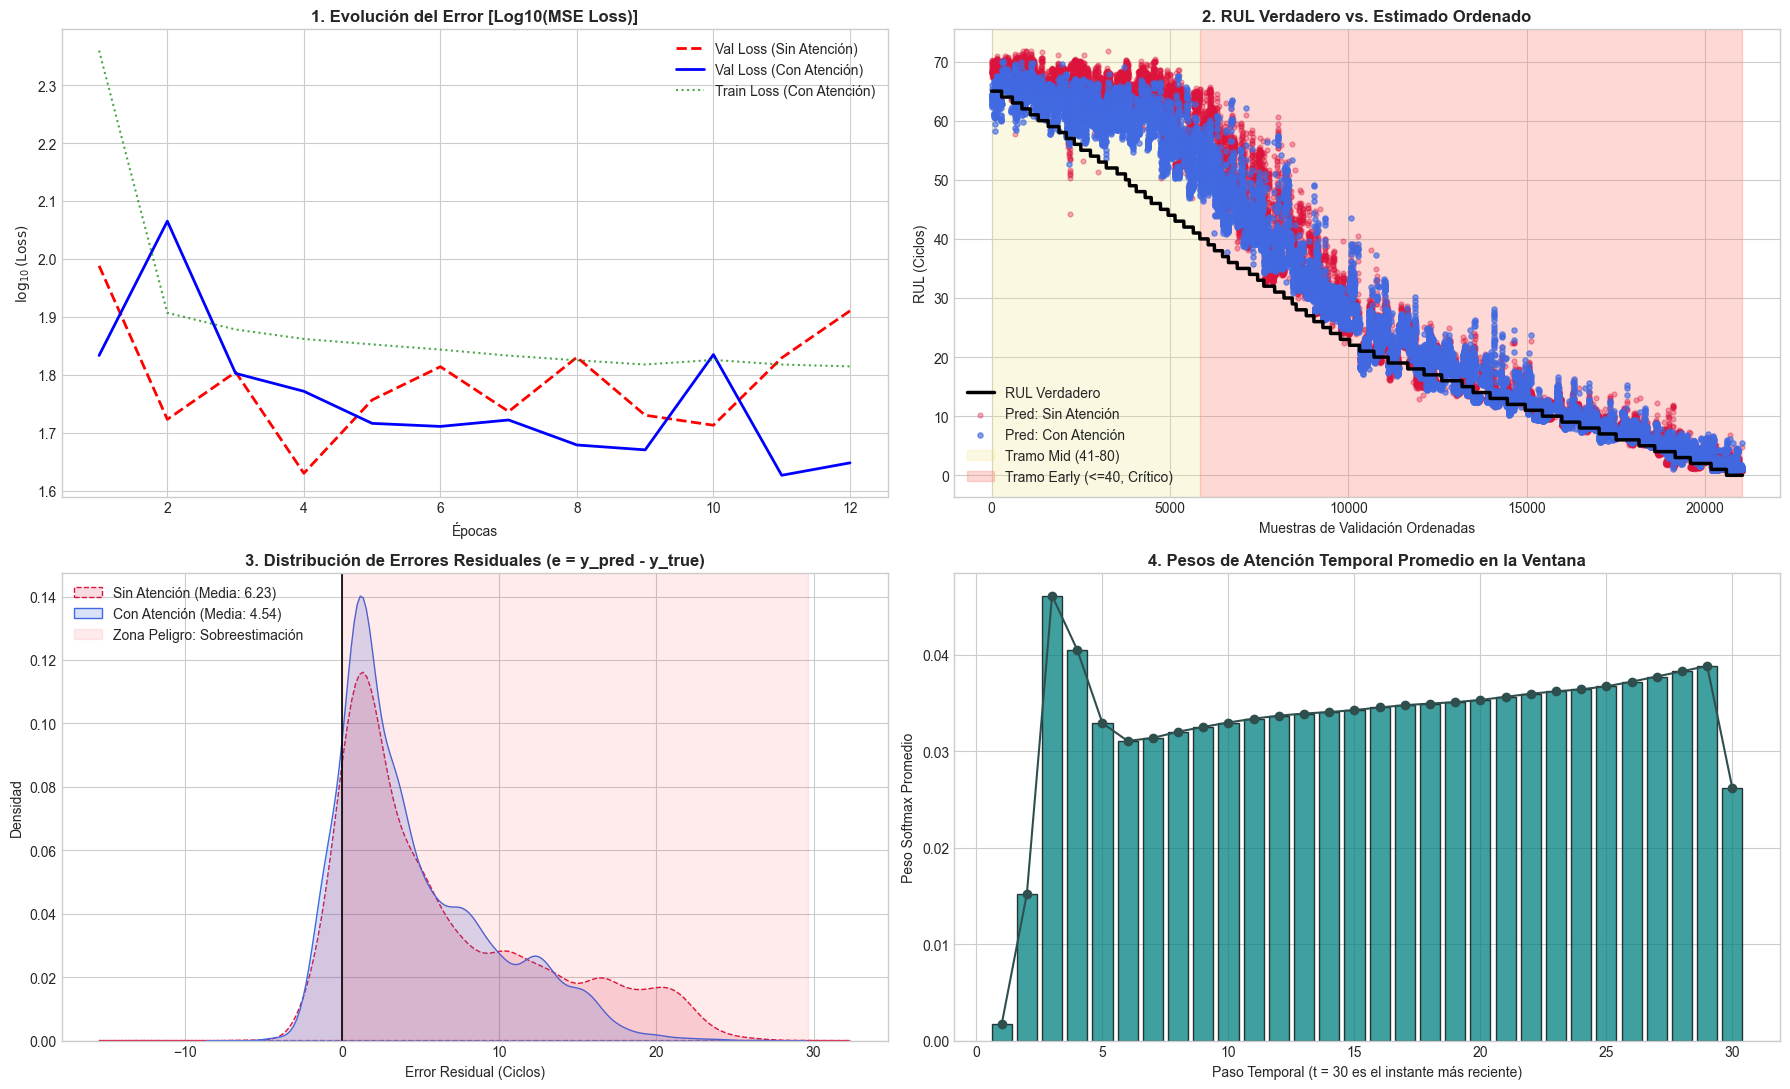

In [72]:
# 1. Función de cálculo protegida con conteo de muestras por tramo
def compute_metrics_safe(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    
    # RMSE Global
    rmse_total = np.sqrt(np.mean((y_pred - y_true)**2))
    
    # NASA Score Asimétrico
    d = y_pred - y_true
    score = np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0))
    
    # Tramos definidos en la memoria base (Araya, 2020)
    mask_early = (y_true <= 40)
    mask_mid = (y_true > 40) & (y_true <= 80)
    mask_late = (y_true > 80)
    
    # Cálculo seguro: Si un tramo no tiene muestras en validación, se marca como NaN
    rmse_e = np.sqrt(np.mean((y_pred[mask_early] - y_true[mask_early])**2)) if np.sum(mask_early) > 0 else np.nan
    rmse_m = np.sqrt(np.mean((y_pred[mask_mid] - y_true[mask_mid])**2)) if np.sum(mask_mid) > 0 else np.nan
    rmse_l = np.sqrt(np.mean((y_pred[mask_late] - y_true[mask_late])**2)) if np.sum(mask_late) > 0 else np.nan
    
    counts = {
        'total': len(y_true),
        'early': int(np.sum(mask_early)),
        'mid': int(np.sum(mask_mid)),
        'late': int(np.sum(mask_late))
    }
    
    return rmse_total, rmse_e, rmse_m, rmse_l, score, counts

# 2. Despliegue seguro de la tabla comparativa
def print_comparative_table_safe(y_true, y_no_att, y_att):
    r_tot_0, r_e_0, r_m_0, r_l_0, sc_0, counts = compute_metrics_safe(y_true, y_no_att)
    r_tot_1, r_e_1, r_m_1, r_l_1, sc_1, _ = compute_metrics_safe(y_true, y_att)
    
    def fmt_val(v):
        return f"{v:.2f}" if not np.isnan(v) else "Sin Muestras"
        
    def fmt_delta(base, new):
        if np.isnan(base) or np.isnan(new) or base == 0:
            return "N/A"
        delta = (base - new) / base * 100
        return f"{delta:+.2f}%"

    summary = pd.DataFrame({
        'Métrica / Tramo': [
            f'RMSE Total (N={counts["total"]})',
            f'RMSE Early [<=40 ciclos] (N={counts["early"]})',
            f'RMSE Mid [41-80 ciclos] (N={counts["mid"]})',
            f'RMSE Late [>80 ciclos] (N={counts["late"]})',
            'Score NASA Asimétrico'
        ],
        'Sin Atención (Baseline)': [
            fmt_val(r_tot_0), fmt_val(r_e_0), fmt_val(r_m_0), fmt_val(r_l_0), f"{sc_0:.1f}"
        ],
        'Con Atención (Propuesta)': [
            fmt_val(r_tot_1), fmt_val(r_e_1), fmt_val(r_m_1), fmt_val(r_l_1), f"{sc_1:.1f}"
        ],
        'Mejora (%)': [
            fmt_delta(r_tot_0, r_tot_1),
            fmt_delta(r_e_0, r_e_1),
            fmt_delta(r_m_0, r_m_1),
            fmt_delta(r_l_0, r_l_1),
            fmt_delta(sc_0, sc_1)
        ]
    })
    
    print("\n" + "="*75)
    print("           TABLA CUANTITATIVA DE ABLACIÓN (N-CMAPSS DS02)")
    print("="*75)
    print(summary.to_string(index=False))
    print("="*75 + "\n")

# 3. Función de gráficos ajustada para tolerar tramos vacíos
def plot_ablation_results_safe(y_test_true, y_pred_no_att, y_pred_att, history_no_att, history_att, attention_weights=None):
    y_test_true = np.array(y_test_true).flatten()
    y_pred_no_att = np.array(y_pred_no_att).flatten()
    y_pred_att = np.array(y_pred_att).flatten()

    fig = plt.figure(figsize=(18, 11))
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

    # GRÁFICO 1: Pérdidas Log10
    ax1 = fig.add_subplot(2, 2, 1)
    epochs = range(1, len(history_att['val_loss']) + 1)
    ax1.plot(epochs, np.log10(history_no_att['val_loss']), 'r--', label='Val Loss (Sin Atención)', lw=2)
    ax1.plot(epochs, np.log10(history_att['val_loss']), 'b-', label='Val Loss (Con Atención)', lw=2)
    ax1.plot(epochs, np.log10(history_att['train_loss']), 'g:', label='Train Loss (Con Atención)', alpha=0.7)
    ax1.set_title("1. Evolución del Error [Log10(MSE Loss)]", fontsize=12, fontweight='bold')
    ax1.set_xlabel("Épocas", fontsize=10)
    ax1.set_ylabel(r"$\log_{10}(\mathrm{Loss})$", fontsize=10)
    ax1.legend(loc='upper right')

    # GRÁFICO 2: Dispersión por Tramos
    ax2 = fig.add_subplot(2, 2, 2)
    sort_idx = np.argsort(y_test_true)[::-1]
    y_true_sorted = y_test_true[sort_idx]
    y_att_sorted = y_pred_att[sort_idx]
    y_no_att_sorted = y_pred_no_att[sort_idx]
    x_axis = np.arange(len(y_true_sorted))

    ax2.plot(x_axis, y_true_sorted, 'k-', lw=2.5, label='RUL Verdadero', zorder=4)
    ax2.scatter(x_axis, y_no_att_sorted, color='crimson', s=12, alpha=0.35, label='Pred: Sin Atención', zorder=2)
    ax2.scatter(x_axis, y_att_sorted, color='royalblue', s=14, alpha=0.65, label='Pred: Con Atención', zorder=3)

    n_late = np.sum(y_true_sorted > 80)
    n_mid = np.sum((y_true_sorted > 40) & (y_true_sorted <= 80))
    n_early = np.sum(y_true_sorted <= 40)

    if n_late > 0:
        ax2.axvspan(0, n_late, color='lightgreen', alpha=0.25, label='Tramo Late (>80)')
    if n_mid > 0:
        ax2.axvspan(n_late, n_late + n_mid, color='khaki', alpha=0.25, label='Tramo Mid (41-80)')
    if n_early > 0:
        ax2.axvspan(n_late + n_mid, len(x_axis), color='salmon', alpha=0.3, label='Tramo Early (<=40, Crítico)')

    ax2.set_title("2. RUL Verdadero vs. Estimado Ordenado", fontsize=12, fontweight='bold')
    ax2.set_xlabel("Muestras de Validación Ordenadas", fontsize=10)
    ax2.set_ylabel("RUL (Ciclos)", fontsize=10)
    ax2.legend(loc='lower left', framealpha=0.9)

    # GRÁFICO 3: Residuos y Sobreestimación
    ax3 = fig.add_subplot(2, 2, 3)
    res_no_att = y_pred_no_att - y_test_true
    res_att = y_pred_att - y_test_true

    sns.kdeplot(res_no_att, ax=ax3, color='crimson', linestyle='--', fill=True, alpha=0.15, label=f'Sin Atención (Media: {res_no_att.mean():.2f})')
    sns.kdeplot(res_att, ax=ax3, color='royalblue', fill=True, alpha=0.2, label=f'Con Atención (Media: {res_att.mean():.2f})')
    ax3.axvline(0, color='black', lw=1.2, linestyle='-')
    max_res = max(res_no_att.max(), res_att.max())
    if max_res > 0:
        ax3.axvspan(0, max_res, color='red', alpha=0.08, label='Zona Peligro: Sobreestimación')
    ax3.set_title("3. Distribución de Errores Residuales (e = y_pred - y_true)", fontsize=12, fontweight='bold')
    ax3.set_xlabel("Error Residual (Ciclos)", fontsize=10)
    ax3.set_ylabel("Densidad", fontsize=10)
    ax3.legend(loc='upper left')

    # GRÁFICO 4: Pesos de Atención
    ax4 = fig.add_subplot(2, 2, 4)
    if attention_weights is not None and len(attention_weights) > 0:
        mean_w = np.mean(attention_weights, axis=0).flatten()
        steps = np.arange(1, len(mean_w) + 1)
        ax4.bar(steps, mean_w, color='teal', alpha=0.75, edgecolor='black')
        ax4.plot(steps, mean_w, color='darkslategrey', marker='o')
        ax4.set_title("4. Pesos de Atención Temporal Promedio en la Ventana", fontsize=12, fontweight='bold')
        ax4.set_xlabel("Paso Temporal (t = 30 es el instante más reciente)", fontsize=10)
        ax4.set_ylabel("Peso Softmax Promedio", fontsize=10)

    plt.tight_layout()
    plt.show()

# Ejecutar visualizaciones con las variables ya existentes en memoria
y_val_eval = y_val.flatten()
print_comparative_table_safe(y_val_eval, preds_no_att, preds_att)
plot_ablation_results_safe(y_val_eval, preds_no_att, preds_att, hist_no_att, hist_att, attn_weights)